# Практика 2.3. Рекуррентная нейронная сеть (SimpleRNN / LSTM)

**Задача:** прогноз электропотребления домохозяйства **на следующий час** по данным за предыдущие 24 часа.

**Датасет:** [Individual Household Electric Power Consumption (UCI)](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption) — ежеминутные измерения в одном доме под Парижем с декабря 2006 по ноябрь 2010 (≈ 2,07 млн строк). Около 1,25 % измерений пропущены — хороший материал для отработки очистки временных рядов.

| Признак | Описание |
|---|---|
| `global_active_power` | активная мощность, кВт — **целевая переменная** |
| `global_reactive_power` | реактивная мощность, кВт |
| `voltage` | напряжение, В |
| `global_intensity` | сила тока, А |
| `sub_metering_1/2/3` | энергия по группам приборов, Вт·ч: кухня / прачечная / водонагреватель и кондиционер |

**Почему RNN:** данные — последовательность, где значение зависит от предыдущих. Рекуррентный слой обрабатывает шаги по очереди и хранит «память» (скрытое состояние). **LSTM** дополнительно имеет механизм вентилей, который решает проблему затухающего градиента и позволяет помнить более длинный контекст. Сравним обычную `SimpleRNN` и `LSTM`.

## 0. Зависимости и импорты

In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn mlflow "tensorflow>=2.16"

In [2]:
import os
import zipfile
from pathlib import Path
from urllib.request import urlretrieve

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import keras
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
from keras import layers
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

## 1. Настройки и вспомогательные функции

In [3]:
EXPERIMENT_NAME = "p2_rnn_power"
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00235/household_power_consumption.zip"
TARGET = "global_active_power"
MEASUREMENTS = ["global_active_power", "global_reactive_power", "voltage", "global_intensity",
                "sub_metering_1", "sub_metering_2", "sub_metering_3"]
VOLTAGE_RANGE = (200, 260)
MIN_MINUTES_PER_HOUR = 30
SHORT_GAP_HOURS = 3
WEEK_HOURS = 24 * 7
WINDOW = 24
TRAIN_SHARE, VAL_SHARE = 0.70, 0.15
BATCH_SIZE = 64
MAX_EPOCHS = 40
LEARNING_RATE = 1e-3
RECURRENT_CELLS = {"simple_rnn": layers.SimpleRNN, "lstm": layers.LSTM}


SEED = 42
ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"
MLFLOW_URI = f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}"

keras.utils.set_random_seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)

mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(EXPERIMENT_NAME)
print(f"Keras {keras.__version__}, backend: {keras.backend.backend()}")


def download(url, filename):
    path = DATA_DIR / filename
    if not path.exists():
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        urlretrieve(url, path)
    return path


def quality_report(frame):
    return pd.DataFrame({
        "dtype": frame.dtypes.astype(str),
        "missing": frame.isna().sum(),
        "missing_%": (frame.isna().mean() * 100).round(2),
        "unique": frame.nunique(),
    })


def iqr_outlier_mask(frame, k=1.5):
    q1, q3 = frame.quantile(0.25), frame.quantile(0.75)
    iqr = q3 - q1
    return (frame < q1 - k * iqr) | (frame > q3 + k * iqr)


class MlflowLogger(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        mlflow.log_metrics({k: float(v) for k, v in (logs or {}).items()}, step=epoch)


def plot_history(history, metric):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, key in zip(axes, ["loss", metric]):
        ax.plot(history.history[key], label="train")
        ax.plot(history.history[f"val_{key}"], label="validation")
        ax.set(title=key, xlabel="эпоха")
        ax.legend()
    plt.tight_layout()
    return fig


def make_windows(features, target, window):
    idx = np.arange(window)[None, :] + np.arange(len(features) - window)[:, None]
    return features[idx], target[window:]


def regression_metrics(y_true, y_pred):
    return {
        "mae": mean_absolute_error(y_true, y_pred),
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "r2": r2_score(y_true, y_pred),
    }

2026/11/10 10:47:59 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/10 10:47:59 INFO mlflow.store.db.utils: Updating database tables
2026/11/10 10:48:07 INFO mlflow.tracking.fluent: Experiment with name 'p2_rnn_power' does not exist. Creating a new experiment.


Keras 3.13.2, backend: tensorflow


**Трекинг экспериментов.** Метрики каждой эпохи пишутся в MLflow через callback `MlflowLogger` (база `mlflow.db` в корне репозитория). Просмотр: `mlflow ui --backend-store-uri sqlite:///mlflow.db` из корня репозитория → http://127.0.0.1:5000.

## 2. Загрузка данных
Архив ≈ 20 МБ (≈ 130 МБ в распакованном виде). Пропуски в исходном файле обозначены `?`. Дата и время хранятся в двух текстовых столбцах — объединяем их в индекс `datetime`.

In [4]:
with zipfile.ZipFile(download(DATA_URL, "household_power_consumption.zip")) as archive:
    txt_name = next(name for name in archive.namelist() if name.endswith(".txt"))
    with archive.open(txt_name) as f:
        raw = pd.read_csv(f, sep=";", na_values=["?"], low_memory=False)

raw.columns = raw.columns.str.lower()
raw["datetime"] = pd.to_datetime(raw["date"] + " " + raw["time"], format="%d/%m/%Y %H:%M:%S")
minute = raw.drop(columns=["date", "time"]).set_index("datetime").sort_index()
minute[MEASUREMENTS] = minute[MEASUREMENTS].apply(pd.to_numeric, errors="coerce")
print(f"Строк: {len(minute):,}; период: {minute.index.min()} — {minute.index.max()}")
minute.head()

Строк: 2,075,259; период: 2006-12-16 17:24:00 — 2010-11-26 21:02:00


,global_active_power,global_reactive_power,voltage,global_intensity,sub_metering_1,sub_metering_2,sub_metering_3
datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


## 3. Качество данных
### 3.1. Пропуски и дубликаты меток времени

In [5]:
quality_report(minute)

,dtype,missing,missing_%,unique
global_active_power,float64,25979,1.25,4186
global_reactive_power,float64,25979,1.25,532
voltage,float64,25979,1.25,2837
global_intensity,float64,25979,1.25,221
sub_metering_1,float64,25979,1.25,88
sub_metering_2,float64,25979,1.25,81
sub_metering_3,float64,25979,1.25,32


In [6]:
dup_timestamps = minute.index.duplicated().sum()
full_range = pd.date_range(minute.index.min(), minute.index.max(), freq="min")
missing_timestamps = len(full_range.difference(minute.index))
rows_all_nan = minute[MEASUREMENTS].isna().all(axis=1).sum()
print(f"Повторяющихся меток времени: {dup_timestamps}")
print(f"Отсутствующих минут в индексе: {missing_timestamps}")
print(f"Строк, где пропущены все измерения: {rows_all_nan:,} — счётчик был отключён целиком")
minute = minute[~minute.index.duplicated(keep="first")]

Повторяющихся меток времени: 0
Отсутствующих минут в индексе: 0
Строк, где пропущены все измерения: 25,979 — счётчик был отключён целиком


Для временного ряда «дубликат» — это **повторяющаяся метка времени**, а не одинаковые значения: одинаковые показания в разные минуты совершенно нормальны. Повторы меток удаляем (оставляем первое измерение).

### 3.2. Физически некорректные значения
- мощности и показания субсчётчиков не могут быть отрицательными;
- напряжение бытовой сети во Франции — 230 В ± 10 %, значения вне 200–260 В — сбой измерения;
- **согласованность:** энергия, учтённая субсчётчиками за минуту, не может превышать общую потреблённую энергию (`global_active_power · 1000 / 60` Вт·ч).

In [7]:
minute_energy_wh = minute[TARGET] * 1000 / 60
sub_sum = minute[["sub_metering_1", "sub_metering_2", "sub_metering_3"]].sum(axis=1, min_count=3)
checks = pd.DataFrame({
    "отрицательные значения": (minute[MEASUREMENTS] < 0).any(axis=1),
    "напряжение вне диапазона": ~minute["voltage"].between(*VOLTAGE_RANGE) & minute["voltage"].notna(),
    "субсчётчики > общего (допуск 1 Вт·ч)": sub_sum > minute_energy_wh + 1,
})
print(checks.sum().to_string())
invalid = checks.any(axis=1)
minute.loc[invalid, MEASUREMENTS] = np.nan
print(f"\nНекорректных строк переведено в пропуски: {invalid.sum():,}")

отрицательные значения                   0
напряжение вне диапазона                 0
субсчётчики > общего (допуск 1 Вт·ч)    33

Некорректных строк переведено в пропуски: 33


**Стратегия обработки пропусков:**
1. Некорректные измерения переводим в пропуски (выше) — дальше обрабатываем их вместе с исходными.
2. **Агрегируем** минутные данные до часовых средних: для прогноза на час вперёд минутная детализация избыточна, а ряд становится в 60 раз короче. Час, в котором валидных минут меньше 30, считаем пропуском — среднее по нескольким минутам ненадёжно.
3. **Короткие разрывы** (≤ 3 часов) заполняем линейной интерполяцией по времени.
4. **Длинные разрывы** (отключения на несколько дней) интерполяция заполнила бы прямой линией, уничтожив суточный цикл. Поэтому заполняем их значением того же часа **неделей ранее** (сезонное заполнение).

Удалять строки нельзя: это разорвало бы последовательность, и окна по 24 часа «склеили» бы несоседние моменты времени.

In [8]:
valid_minutes = minute[TARGET].resample("h").count()
hourly = minute[MEASUREMENTS].resample("h").mean()
hourly.loc[valid_minutes < MIN_MINUTES_PER_HOUR] = np.nan
missing_before = hourly[TARGET].isna().sum()

hourly = hourly.interpolate(method="time", limit=SHORT_GAP_HOURS, limit_area="inside")
after_short = hourly[TARGET].isna().sum()
for _ in range(3):
    hourly = hourly.fillna(hourly.shift(WEEK_HOURS))
hourly = hourly.interpolate(method="time").bfill()

print(f"Часов всего: {len(hourly):,}")
print(f"Пропущенных часов: {missing_before} → после интерполяции коротких: {after_short} → итог: {hourly[TARGET].isna().sum()}")

Часов всего: 34,589
Пропущенных часов: 432 → после интерполяции коротких: 405 → итог: 0


### 3.3. Выбросы

global_active_power       738
global_reactive_power    1672
voltage                  1118
global_intensity          830
sub_metering_1           5006
sub_metering_2           2591
sub_metering_3              0


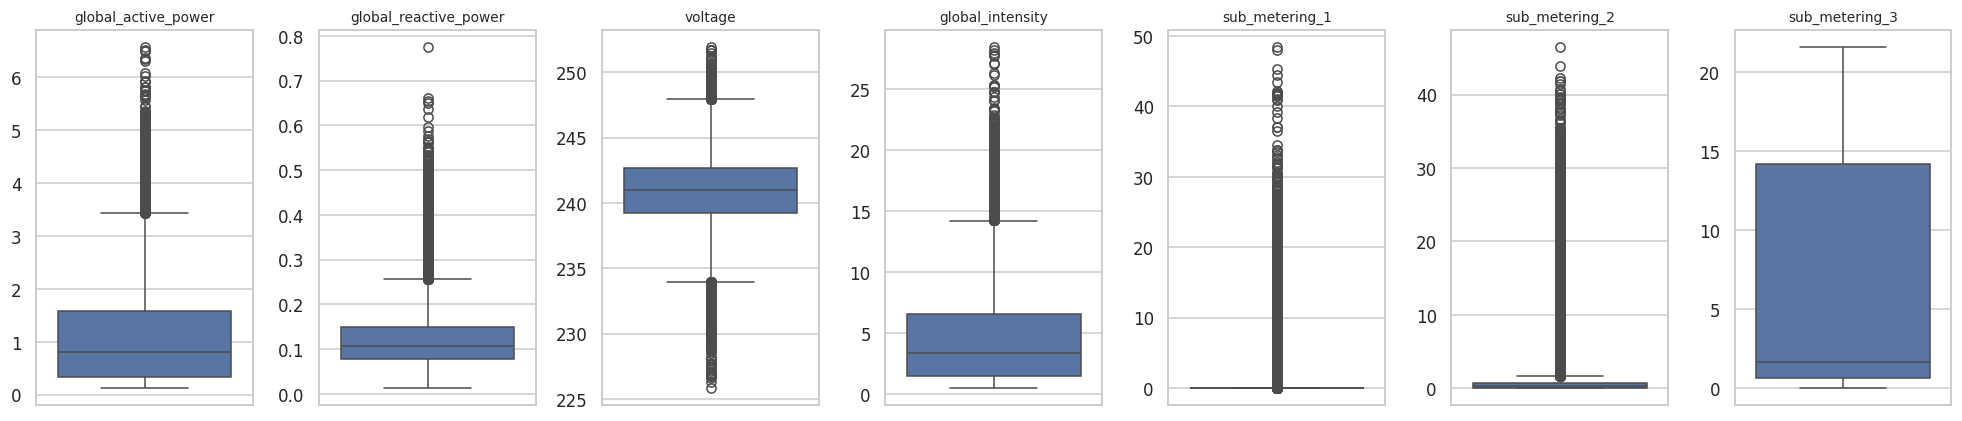

In [9]:
outliers = iqr_outlier_mask(hourly).sum()
print(outliers.to_string())
fig, axes = plt.subplots(1, len(MEASUREMENTS), figsize=(18, 4))
for ax, col in zip(axes, MEASUREMENTS):
    sns.boxplot(y=hourly[col], ax=ax)
    ax.set_title(col, fontsize=9)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

Выбросы по IQR в мощности — это пики потребления (включены духовка, стиральная машина и водонагреватель одновременно). Это **реальные и самые важные для прогноза** события, поэтому их не удаляем. Ошибки измерений уже отсеяны физическими проверками выше.

## 4. Разведочный анализ (EDA)

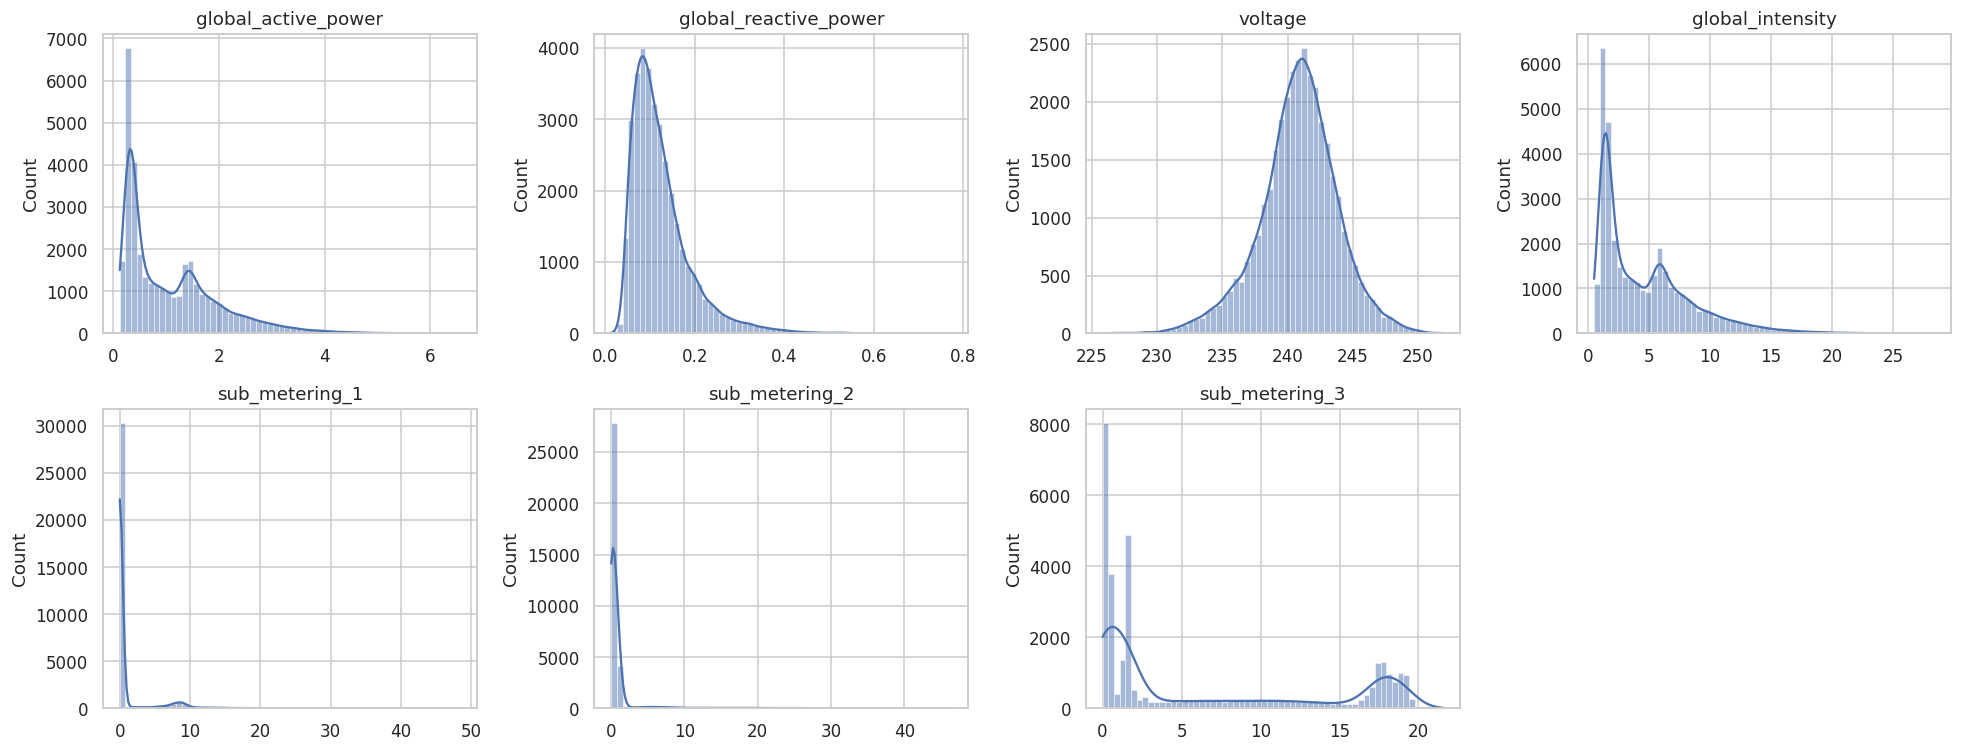

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.ravel(), MEASUREMENTS):
    sns.histplot(hourly[col], bins=60, kde=True, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
axes.ravel()[-1].set_visible(False)
plt.tight_layout()
plt.show()

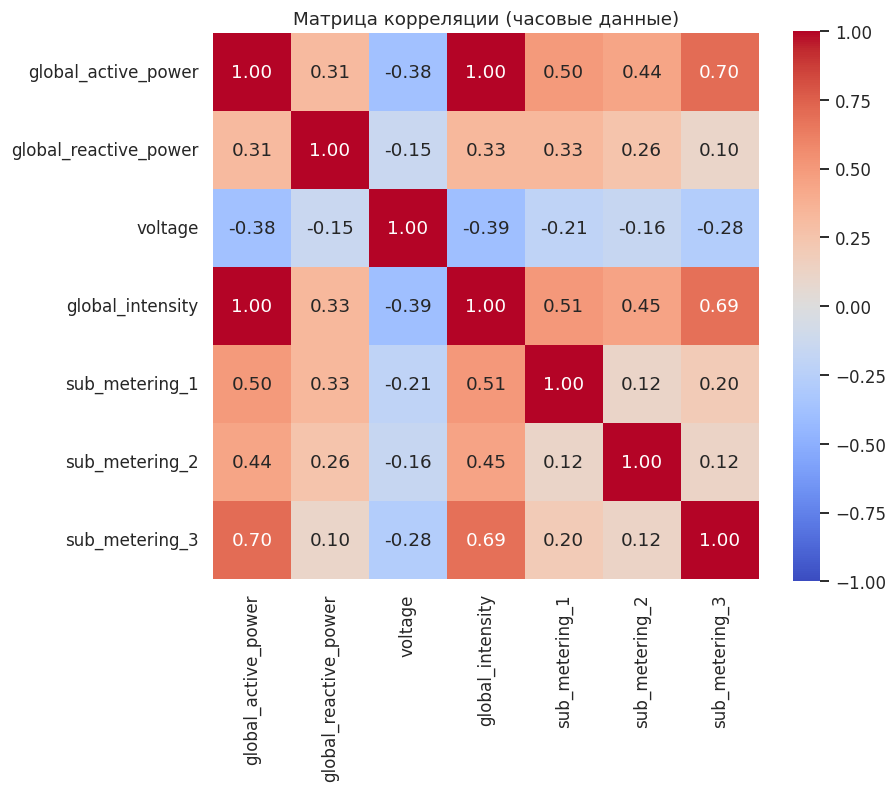

In [11]:
plt.figure(figsize=(8, 6.5))
sns.heatmap(hourly.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Матрица корреляции (часовые данные)")
plt.show()

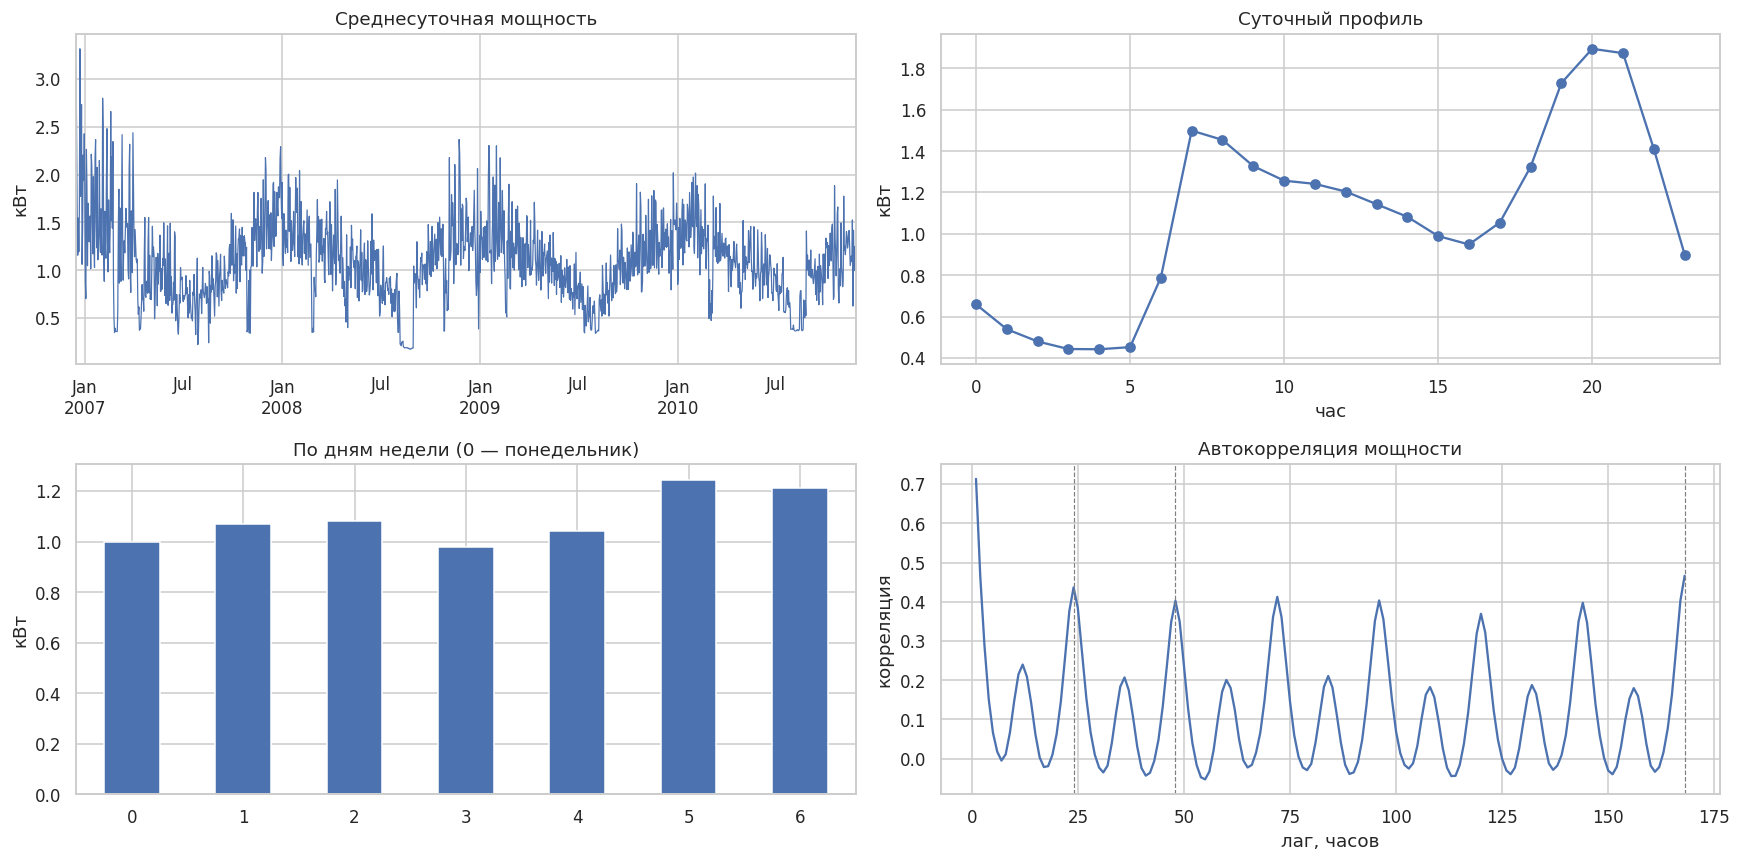

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(16, 8))
hourly[TARGET].resample("D").mean().plot(ax=axes[0, 0], lw=0.8)
axes[0, 0].set(title="Среднесуточная мощность", ylabel="кВт", xlabel="")
hourly.groupby(hourly.index.hour)[TARGET].mean().plot(ax=axes[0, 1], marker="o")
axes[0, 1].set(title="Суточный профиль", xlabel="час", ylabel="кВт")
hourly.groupby(hourly.index.dayofweek)[TARGET].mean().plot.bar(ax=axes[1, 0], rot=0)
axes[1, 0].set(title="По дням недели (0 — понедельник)", ylabel="кВт", xlabel="")
lags = range(1, WEEK_HOURS + 1)
axes[1, 1].plot(lags, [hourly[TARGET].autocorr(lag) for lag in lags])
axes[1, 1].set(title="Автокорреляция мощности", xlabel="лаг, часов", ylabel="корреляция")
for lag in (24, 48, 168):
    axes[1, 1].axvline(lag, color="gray", linestyle="--", lw=0.8)
plt.tight_layout()
plt.show()

**Наблюдения EDA:**
- выражена **годовая сезонность**: зимой среднесуточная мощность ≈ 1,5–2 кВт, летом ≈ 0,5–1 кВт; в августе видны провалы до ~0,3 кВт — семья в отпуске;
- **суточный профиль**: ночной минимум ≈ 0,45 кВт (3–5 ч), утренний пик ≈ 1,5 кВт (7 ч) и главный вечерний пик ≈ 1,9 кВт (20–21 ч);
- в **выходные** (сб, вс) потребление выше (≈ 1,2 кВт против ≈ 1,0 кВт в будни) — люди дома;
- **автокорреляция** 0,71 на лаге 1 час и пики ≈ 0,4–0,47 на лагах 24, 48, …, 168 часов — прошлое действительно предсказывает будущее, что и использует рекуррентная сеть;
- `global_intensity` полностью коррелирует с мощностью (1,00, так как P ≈ U·I), из субсчётчиков сильнее всего связан водонагреватель/кондиционер `sub_metering_3` (0,70); напряжение связано умеренно отрицательно (−0,38) — под нагрузкой оно проседает.

In [13]:
features = hourly.copy()
features["hour_sin"] = np.sin(2 * np.pi * features.index.hour / 24)
features["hour_cos"] = np.cos(2 * np.pi * features.index.hour / 24)
features["dow_sin"] = np.sin(2 * np.pi * features.index.dayofweek / 7)
features["dow_cos"] = np.cos(2 * np.pi * features.index.dayofweek / 7)
feature_cols = list(features.columns)

n = len(features)
train_end, val_end = int(n * TRAIN_SHARE), int(n * (TRAIN_SHARE + VAL_SHARE))
parts = {"train": features.iloc[:train_end], "val": features.iloc[train_end:val_end], "test": features.iloc[val_end:]}
for name, part in parts.items():
    print(f"{name:>5}: {part.index.min():%Y-%m-%d} — {part.index.max():%Y-%m-%d}, {len(part)} часов")

feature_scaler = StandardScaler().fit(parts["train"][feature_cols])
target_scaler = StandardScaler().fit(parts["train"][[TARGET]])

data = {}
for name, part in parts.items():
    X_part = feature_scaler.transform(part[feature_cols]).astype("float32")
    y_part = target_scaler.transform(part[[TARGET]]).ravel().astype("float32")
    data[name] = make_windows(X_part, y_part, WINDOW)
    data[f"{name}_raw_target"] = part[TARGET].to_numpy()
    print(f"{name:>5}: X {data[name][0].shape}, y {data[name][1].shape}")

train: 2006-12-16 — 2009-09-20, 24212 часов
  val: 2009-09-20 — 2010-04-24, 5188 часов
 test: 2010-04-24 — 2010-11-26, 5189 часов
train: X (24188, 24, 11), y (24188,)
  val: X (5164, 24, 11), y (5164,)
 test: X (5165, 24, 11), y (5165,)


### Наивные базовые прогнозы
Нейросеть имеет смысл, только если она лучше простых правил:
- **persistence** — «через час будет столько же, сколько сейчас»;
- **сезонный наивный** — «столько же, сколько в этот час вчера».

In [14]:
test_raw = data["test_raw_target"]
y_test_true = test_raw[WINDOW:]
baselines = {
    "persistence": test_raw[WINDOW - 1:-1],
    "seasonal_naive_24h": test_raw[WINDOW - 24:-24],
}
baseline_metrics = {name: regression_metrics(y_test_true, pred) for name, pred in baselines.items()}
pd.DataFrame(baseline_metrics).T

,mae,rmse,r2
persistence,0.382933,0.581707,0.321643
seasonal_naive_24h,0.502892,0.749945,-0.127479


## 6. Архитектура
`Input(24, 11)` → рекуррентный слой (64 нейрона) → `Dropout` → `Dense(16, ReLU)` → `Dense(1)`

Рекуррентный слой читает 24 часовых шага по порядку и возвращает финальное скрытое состояние — «сжатое резюме» последних суток. Выходной слой без активации (регрессия), функция потерь — MSE.

In [15]:
def build_recurrent(cell_name, units=64, dropout=0.2):
    inputs = keras.Input(shape=(WINDOW, len(feature_cols)), name="sequence")
    x = RECURRENT_CELLS[cell_name](units, name=cell_name)(inputs)
    x = layers.Dropout(dropout, name="dropout")(x)
    x = layers.Dense(16, activation="relu", name="dense")(x)
    outputs = layers.Dense(1, name="next_hour_power")(x)
    model = keras.Model(inputs, outputs, name=f"{cell_name}_forecaster")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss="mse", metrics=["mae"])
    return model


build_recurrent("lstm").summary()

Model: "lstm_forecaster"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequence (InputLayer)           │ (None, 24, 11)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        19,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ next_hour_power (Dense)         │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,513 (80.13 KB)

 Trainable params: 20,513 (80.13 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Обучение и выбор модели на валидации

In [16]:
X_train, y_train = data["train"]
X_val, y_val = data["val"]
X_test = data["test"][0]

models, histories, val_results = {}, {}, {}
for cell_name in RECURRENT_CELLS:
    model = build_recurrent(cell_name)
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
        MlflowLogger(),
    ]
    with mlflow.start_run(run_name=cell_name):
        mlflow.log_params({"cell": cell_name, "units": 64, "window": WINDOW, "lr": LEARNING_RATE,
                           "batch_size": BATCH_SIZE, "n_params": model.count_params()})
        history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=MAX_EPOCHS,
                            batch_size=BATCH_SIZE, callbacks=callbacks, verbose=0)
        val_pred = target_scaler.inverse_transform(model.predict(X_val, verbose=0)).ravel()
        metrics = regression_metrics(data["val_raw_target"][WINDOW:], val_pred)
        mlflow.log_metrics({f"val_{k}_kw": v for k, v in metrics.items()})
    models[cell_name], histories[cell_name], val_results[cell_name] = model, history, metrics
    print(f"{cell_name}: {len(history.history['loss'])} эпох, val MAE = {metrics['mae']:.4f} кВт")

pd.DataFrame(val_results).T

simple_rnn: 19 эпох, val MAE = 0.3717 кВт
lstm: 21 эпох, val MAE = 0.3624 кВт


,mae,rmse,r2
simple_rnn,0.371711,0.537199,0.633634
lstm,0.362351,0.528720,0.645109


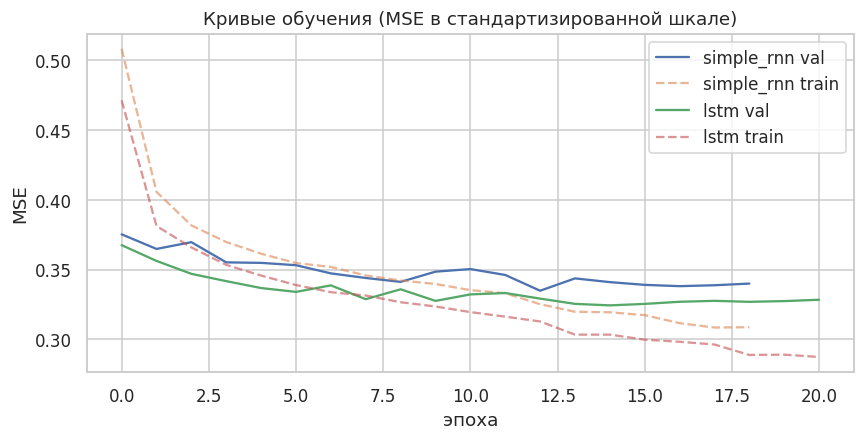

Лучшая модель по val MAE: lstm


In [17]:
fig, ax = plt.subplots(figsize=(9, 4))
for cell_name, history in histories.items():
    ax.plot(history.history["val_loss"], label=f"{cell_name} val")
    ax.plot(history.history["loss"], linestyle="--", alpha=0.6, label=f"{cell_name} train")
ax.set(title="Кривые обучения (MSE в стандартизированной шкале)", xlabel="эпоха", ylabel="MSE")
ax.legend()
history_fig = fig
plt.show()

best_cell = min(val_results, key=lambda c: val_results[c]["mae"])
best_model = models[best_cell]
print(f"Лучшая модель по val MAE: {best_cell}")

## 8. Оценка на тестовой выборке

In [18]:
test_pred = target_scaler.inverse_transform(best_model.predict(X_test, verbose=0)).ravel()
test_metrics = regression_metrics(y_test_true, test_pred)
comparison = pd.DataFrame({**baseline_metrics, best_cell: test_metrics}).T
comparison["улучшение MAE vs persistence"] = 1 - comparison["mae"] / comparison.loc["persistence", "mae"]
comparison.round(4)

,mae,rmse,r2,улучшение MAE vs persistence
persistence,0.3829,0.5817,0.3216,0.0000
seasonal_naive_24h,0.5029,0.7499,-0.1275,-0.3133
lstm,0.3120,0.4555,0.5841,0.1852


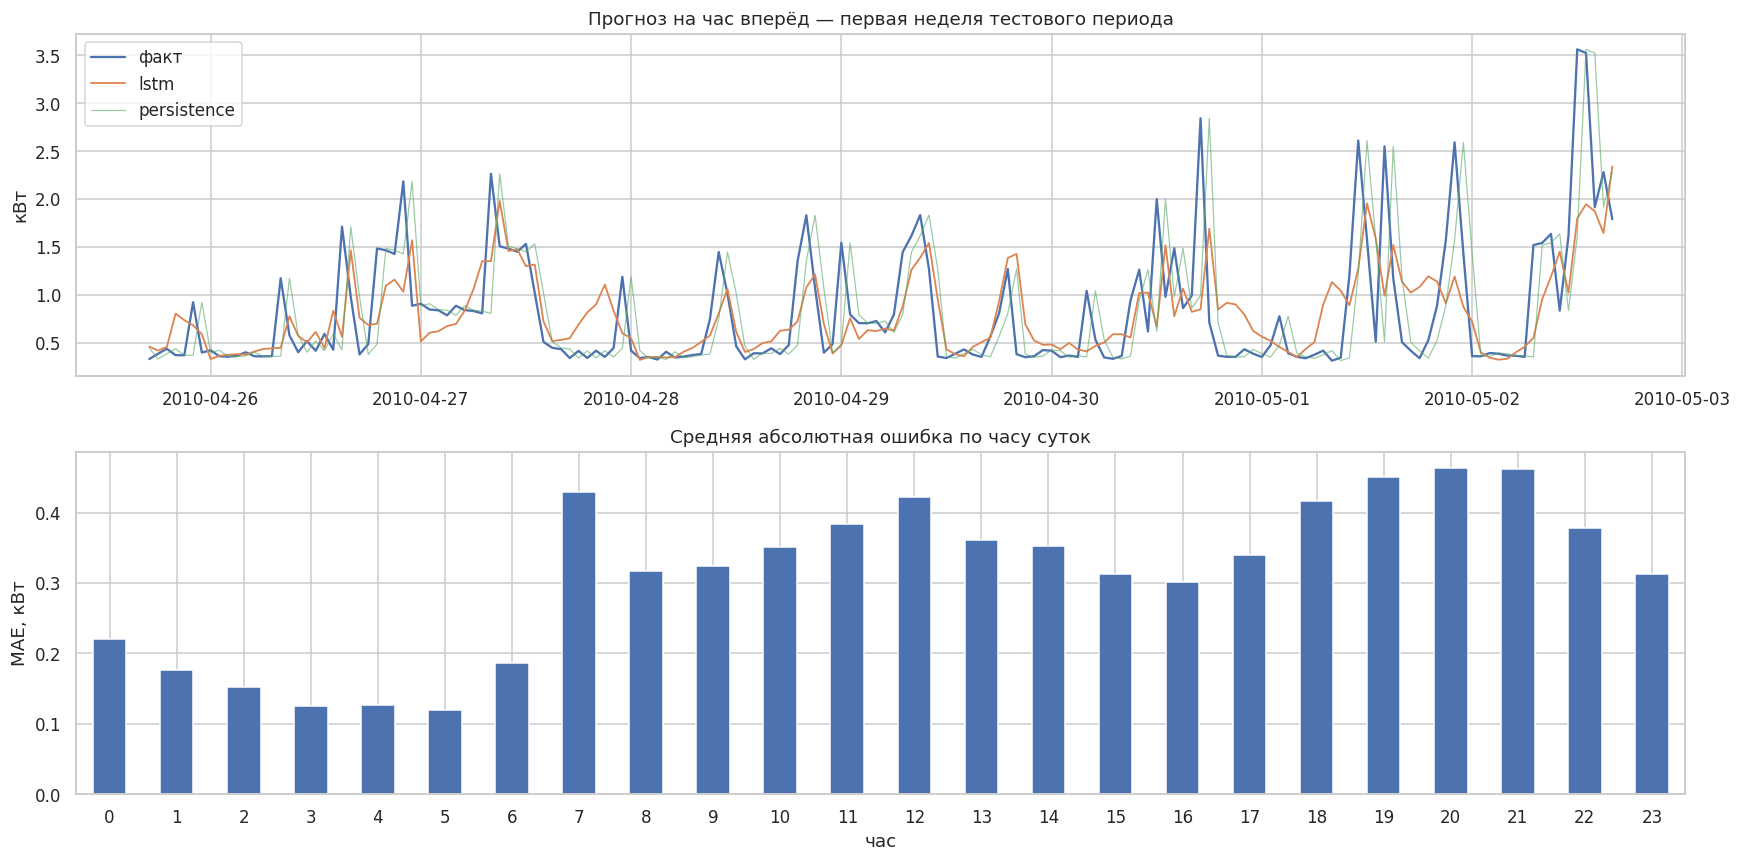

In [19]:
test_index = parts["test"].index[WINDOW:]
week = slice(0, WEEK_HOURS)
fig, axes = plt.subplots(2, 1, figsize=(16, 8))
axes[0].plot(test_index[week], y_test_true[week], label="факт", lw=1.5)
axes[0].plot(test_index[week], test_pred[week], label=best_cell, lw=1.2)
axes[0].plot(test_index[week], baselines["persistence"][week], label="persistence", lw=0.8, alpha=0.6)
axes[0].set(title="Прогноз на час вперёд — первая неделя тестового периода", ylabel="кВт")
axes[0].legend()
abs_err = pd.Series(np.abs(y_test_true - test_pred), index=test_index)
abs_err.groupby(abs_err.index.hour).mean().plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Средняя абсолютная ошибка по часу суток", xlabel="час", ylabel="MAE, кВт")
plt.tight_layout()
plt.show()

In [20]:
with mlflow.start_run(run_name=f"{best_cell}_test"):
    mlflow.log_params({"cell": best_cell, "window": WINDOW})
    mlflow.log_metrics({f"test_{k}_kw": v for k, v in test_metrics.items()})
    mlflow.log_metrics({f"baseline_persistence_test_{k}_kw": v for k, v in baseline_metrics["persistence"].items()})
    mlflow.log_figure(fig, "test_forecast.png")
    mlflow.log_figure(history_fig, "learning_curves.png")
print("Результаты записаны в MLflow")

Результаты записаны в MLflow


## 9. Выводы
- **Качество данных.** Из 2 075 259 минутных записей 25 979 (1,25 %) были пропусками — счётчик отключался целиком; ещё 33 записи с физически некорректными значениями (субсчётчики больше общего потребления) переведены в пропуски. Повторов меток времени и пропущенных минут в индексе нет. После агрегации до 34 589 часов пропущенными оказались 432 часа: 27 часов в коротких разрывах заполнены интерполяцией, оставшиеся 405 часов длинных отключений — значениями того же часа неделей ранее. Выбросы (пики потребления) сохранены как реальные события.
- **Разбиение по времени:** train — дек. 2006 – сент. 2009, val — сент. 2009 – апр. 2010, test — апр. – нояб. 2010; окно 24 часа × 11 признаков.
- **Сравнение ячеек на валидации:** SimpleRNN — MAE 0,372 кВт, **LSTM — 0,362 кВт** (R² 0,645 против 0,634). LSTM выигрывает немного: окно в 24 шага достаточно короткое, и проблема затухающего градиента у SimpleRNN проявляется слабо.
- **Итог на тесте:** LSTM — MAE **0,312 кВт**, RMSE **0,456 кВт**, R² **0,584**. Наивный прогноз «как час назад» — MAE 0,383 (R² 0,32), «как вчера в это же время» — MAE 0,503 (R² < 0). LSTM снижает ошибку на **18,5 %** относительно лучшего наивного прогноза.
- **Ограничения.** На графике видно, что модель хорошо повторяет суточный ритм, но сглаживает резкие пики. Наибольшие ошибки — в 7 ч и 18–21 ч (MAE ≈ 0,42–0,46 кВт), ночью ошибка минимальна (≈ 0,12 кВт). Пиковое включение мощных приборов во многом случайно и плохо предсказуемо по истории потребления.